# Colegio Universitario de Cartago CUC
#### Profesor: Ronald Cordoba Vega
#### Estudiantes:
- Tiffany Daniela Méndez Quirós
- Mariel Rodriguez Arguello
- Monica
- Isaac Ulloa
- Wedell Orozco González

### Proposito general:
Diseñar e implementar un flujo de trabajo automatizado (pipeline) basado
en Programación Orientada a Objetos (POO) que integre las fases del ciclo
de vida de un proyecto de minería de datos, alcanzando a utilizar la
metodología estándar CRISP-DM. El proyecto deberá evidenciar la
capacidad de procesar, transformar y modelar datos para tomar
decisiones basadas en estos.

## 1. Librerias

In [1]:
import pandas as pd
import sys
from pathlib import Path

raiz_proyecto = Path.cwd().parent
sys.path.append(str(raiz_proyecto))

from CLASES_POO.POO import about_data, Reglas_Asociacion

## 2. Ingesta de datos

In [2]:
raw_songs = about_data(r"\Habitos-Musicales\DATA\RAW\music_streaming_habits_2026.csv")

Datos cargados con éxito desde la ruta


In [3]:
raw_songs.datos

,listener_id,age,country,platform,subscription,top_genre,top_artist,daily_listening_minutes,songs_per_day,playlists_count,skip_rate_pct,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too
0,1,24,Australia,Apple Music,Free,R&B,Kendrick Lamar,191,54,9,39.3,False,Sleep,False,True
1,2,21,Germany,Spotify,Free,Classical,Drake,249,68,10,18.3,True,Workout,True,True
2,3,32,Japan,Amazon Music,Free,Hip-Hop,Olivia Rodrigo,49,11,11,22.7,True,Sad,False,True
3,4,39,Japan,Apple Music,Free,Pop,Burna Boy,96,22,8,29.4,True,Sad,True,False
4,5,23,India,Spotify,Family,Country,Olivia Rodrigo,100,24,13,37.7,True,Workout,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3996,26,France,Spotify,Family,Pop,SZA,197,55,6,15.3,False,Workout,True,False
3996,3997,35,Germany,YouTube Music,Free,Rock,Ariana Grande,320,77,13,9.2,True,Sad,False,True
3997,3998,43,India,Apple Music,Free,Hip-Hop,Dua Lipa,99,38,5,14.0,False,Happy,True,True
3998,3999,26,India,Apple Music,Student,Indie,SZA,76,31,7,36.1,False,Happy,False,False


## 3. Exploración y transformación de datos


In [4]:
# Utilización de la función creada en el archivo "clean.py" clase limpiador de datos
raw_songs.reporte_calidad()

=== Reporte de Diagnóstico y Calidad ===
Total de registros: 4000
Registros duplicados: 0

Detalle de campos y valores faltantes:
No se detectaron valores nulos.


,Tipo de Dato,Valores Nulos,% Nulos
listener_id,int64,0,0.0
age,int64,0,0.0
country,object,0,0.0
platform,object,0,0.0
subscription,object,0,0.0
top_genre,object,0,0.0
top_artist,object,0,0.0
daily_listening_minutes,int64,0,0.0
songs_per_day,int64,0,0.0
playlists_count,int64,0,0.0


In [5]:
# Valores min, max, media ect... de las columnas
raw_songs.datos.describe()

,listener_id,age,daily_listening_minutes,songs_per_day,playlists_count,skip_rate_pct
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,2000.500000,27.849000,138.702750,39.137500,8.994500,28.163375
std,1154.844867,8.595881,86.296023,25.046296,3.027914,11.815850
min,1.000000,13.000000,5.000000,1.000000,1.000000,0.000000
25%,1000.750000,22.000000,74.000000,21.000000,7.000000,20.000000
50%,2000.500000,28.000000,122.000000,35.000000,9.000000,28.100000
75%,3000.250000,34.000000,185.000000,52.250000,11.000000,36.300000
max,4000.000000,57.000000,697.000000,198.000000,22.000000,70.900000


In [6]:
# Utilización de la función creada en el archivo "POO.py" clase about_data
# Muestra el total de categorías y la distribución para todas las columnas de texto.
raw_songs.resumen_categoricas()

=== RESUMEN DE VARIABLES CATEGÓRICAS (6 columnas) ===

Columna: 'country' | Total valores únicos: 10
------------------------------------------------------------
country
Japan        439
Canada       429
USA          418
Brazil       409
Nigeria      401
Australia    397
India        390
France       377
Germany      371
UK           369
Name: count, dtype: int64

Columna: 'platform' | Total valores únicos: 6
------------------------------------------------------------
platform
Spotify          1591
Apple Music       906
YouTube Music     689
Amazon Music      315
SoundCloud        278
Tidal             221
Name: count, dtype: int64

Columna: 'subscription' | Total valores únicos: 4
------------------------------------------------------------
subscription
Free       1820
Premium    1193
Family      586
Student     401
Name: count, dtype: int64

Columna: 'top_genre' | Total valores únicos: 12
------------------------------------------------------------
top_genre
Pop          721
Hip-Hop

In [26]:
# Selección de columnas necesarias
use_songs = raw_songs.datos[["age", "platform", "subscription", "top_genre", "daily_listening_minutes", "discover_weekly_user", "top_mood", "uses_offline_mode", "podcasts_too"]].copy()
use_songs = about_data(use_songs)
use_songs.datos

Datos cargados con éxito a partir de la tabla


,age,platform,subscription,top_genre,daily_listening_minutes,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too
0,24,Apple Music,Free,R&B,191,False,Sleep,False,True
1,21,Spotify,Free,Classical,249,True,Workout,True,True
2,32,Amazon Music,Free,Hip-Hop,49,True,Sad,False,True
3,39,Apple Music,Free,Pop,96,True,Sad,True,False
4,23,Spotify,Family,Country,100,True,Workout,True,True
...,...,...,...,...,...,...,...,...,...
3995,26,Spotify,Family,Pop,197,False,Workout,True,False
3996,35,YouTube Music,Free,Rock,320,True,Sad,False,True
3997,43,Apple Music,Free,Hip-Hop,99,False,Happy,True,True
3998,26,Apple Music,Student,Indie,76,False,Happy,False,False


#### Tranformación de variables age y daily_listening_minutes


In [27]:
# 1. Categorizar 'age' con etapas de vida realistas
use_songs.datos['age_group'] = pd.cut(
    use_songs.datos['age'],
    bins=[-1, 18, 26, 40, 120],
    labels=['Menor', 'Joven_Adulto', 'Adulto', 'Adulto_Maduro']
)
use_songs.datos.drop(columns=['age'], inplace=True)

# 2. Categorizar 'daily_listening_minutes' y eliminar la columna numérica original
use_songs.datos['listening_level'] = pd.cut(
    use_songs.datos['daily_listening_minutes'],
    bins=[-1, 60, 120, 1440],
    labels=['Escucha_Baja', 'Escucha_Media', 'Escucha_Alta']
)
use_songs.datos.drop(columns=['daily_listening_minutes'], inplace=True)

# 3. Mostrar las primeras filas (use_songs sigue siendo tu objeto LimpiadorDatos)
use_songs.datos.head()

,platform,subscription,top_genre,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too,age_group,listening_level
0,Apple Music,Free,R&B,False,Sleep,False,True,Joven_Adulto,Escucha_Alta
1,Spotify,Free,Classical,True,Workout,True,True,Joven_Adulto,Escucha_Alta
2,Amazon Music,Free,Hip-Hop,True,Sad,False,True,Adulto,Escucha_Baja
3,Apple Music,Free,Pop,True,Sad,True,False,Adulto,Escucha_Media
4,Spotify,Family,Country,True,Workout,True,True,Joven_Adulto,Escucha_Media


In [28]:
use_songs.datos

,platform,subscription,top_genre,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too,age_group,listening_level
0,Apple Music,Free,R&B,False,Sleep,False,True,Joven_Adulto,Escucha_Alta
1,Spotify,Free,Classical,True,Workout,True,True,Joven_Adulto,Escucha_Alta
2,Amazon Music,Free,Hip-Hop,True,Sad,False,True,Adulto,Escucha_Baja
3,Apple Music,Free,Pop,True,Sad,True,False,Adulto,Escucha_Media
4,Spotify,Family,Country,True,Workout,True,True,Joven_Adulto,Escucha_Media
...,...,...,...,...,...,...,...,...,...
3995,Spotify,Family,Pop,False,Workout,True,False,Joven_Adulto,Escucha_Alta
3996,YouTube Music,Free,Rock,True,Sad,False,True,Adulto,Escucha_Alta
3997,Apple Music,Free,Hip-Hop,False,Happy,True,True,Adulto_Maduro,Escucha_Media
3998,Apple Music,Student,Indie,False,Happy,False,False,Joven_Adulto,Escucha_Media


In [10]:
# Utilización de la función creada en el archivo "POO.py" clase about_data (se le aplico a los datos iniciales de momento no utilizada)
#use_songs.estandarizar()

In [29]:
# Utilización de la función creada en el archivo "POO.py" clase about_data
# Muestra el total de categorías y la distribución para todas las columnas de texto sobre los datos a utilizar.
use_songs.resumen_categoricas()

=== RESUMEN DE VARIABLES CATEGÓRICAS (6 columnas) ===

Columna: 'platform' | Total valores únicos: 6
------------------------------------------------------------
platform
Spotify          1591
Apple Music       906
YouTube Music     689
Amazon Music      315
SoundCloud        278
Tidal             221
Name: count, dtype: int64

Columna: 'subscription' | Total valores únicos: 4
------------------------------------------------------------
subscription
Free       1820
Premium    1193
Family      586
Student     401
Name: count, dtype: int64

Columna: 'top_genre' | Total valores únicos: 12
------------------------------------------------------------
top_genre
Pop          721
Hip-Hop      605
Rock         472
EDM          382
R&B          341
Indie        327
K-Pop        278
Afrobeats    210
Lo-fi        201
Classical    166
Name: count, dtype: int64
... y 2 valores más.

Columna: 'top_mood' | Total valores únicos: 8
------------------------------------------------------------
top_mood
Sa

In [30]:
# Convierte variables categóricas en columnas binarias (True/False)
use_songs = pd.get_dummies(use_songs.datos, prefix_sep=': ', dtype=bool)

In [13]:
use_songs = about_data(use_songs)

Datos cargados con éxito a partir de la tabla


In [14]:
use_songs.datos

,discover_weekly_user,uses_offline_mode,podcasts_too,platform: Amazon Music,platform: Apple Music,platform: SoundCloud,platform: Spotify,platform: Tidal,platform: YouTube Music,subscription: Family,...,top_mood: Party,top_mood: Sad,top_mood: Sleep,top_mood: Workout,age_group: Menor,age_group: Joven,age_group: Adulto,listening_level: Escucha_Baja,listening_level: Escucha_Media,listening_level: Escucha_Alta
0,False,False,True,False,True,False,False,False,False,False,...,False,False,True,False,False,True,False,False,False,True
1,True,True,True,False,False,False,True,False,False,False,...,False,False,False,True,False,True,False,False,False,True
2,True,False,True,True,False,False,False,False,False,False,...,False,True,False,False,False,True,False,True,False,False
3,True,True,False,False,True,False,False,False,False,False,...,False,True,False,False,False,True,False,False,True,False
4,True,True,True,False,False,False,True,False,False,True,...,False,False,False,True,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,False,True,False,False,False,False,True,False,False,True,...,False,False,False,True,False,True,False,False,False,True
3996,True,False,True,False,False,False,False,False,True,False,...,False,True,False,False,False,True,False,False,False,True
3997,False,True,True,False,True,False,False,False,False,False,...,False,False,False,False,False,False,True,False,True,False
3998,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False


## 4. Reglas de asociación Apriori, FP-Growth y Eclat

In [51]:
fp_model = Reglas_Asociacion(use_songs)

#### Apriori

In [52]:
# 2. Entrenar ('fpgrowth', 'apriori' o 'eclat')
fp_model.fit(metodo='apriori', min_support=0.03, min_confidence=0.5)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(uses_offline_mode),(discover_weekly_user),0.42750,0.57000,0.24775,0.579532,1.016723,1.0,0.004075,1.022670,0.028730,0.330443,0.022168,0.507091
1,(podcasts_too),(discover_weekly_user),0.46800,0.57000,0.26400,0.564103,0.989654,1.0,-0.002760,0.986471,-0.019273,0.341085,-0.013715,0.513630
2,(platform: Amazon Music),(discover_weekly_user),0.07875,0.57000,0.04425,0.561905,0.985798,1.0,-0.000637,0.981522,-0.015398,0.073201,-0.018826,0.319768
3,(platform: Apple Music),(discover_weekly_user),0.22650,0.57000,0.12975,0.572848,1.004996,1.0,0.000645,1.006667,0.006427,0.194601,0.006623,0.400240
4,(platform: SoundCloud),(discover_weekly_user),0.06950,0.57000,0.04150,0.597122,1.047583,1.0,0.001885,1.067321,0.048814,0.069398,0.063075,0.334965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342,"(listening_level: Escucha_Media, podcasts_too,...",(age_group: Adulto),0.06550,0.47575,0.03350,0.511450,1.075040,1.0,0.002338,1.073074,0.074695,0.065977,0.068098,0.290933
343,"(podcasts_too, subscription: Premium, age_grou...",(listening_level: Escucha_Alta),0.06550,0.50850,0.03475,0.530534,1.043332,1.0,0.001443,1.046935,0.044443,0.064441,0.044831,0.299436
344,"(listening_level: Escucha_Alta, subscription: ...",(age_group: Adulto),0.06650,0.47575,0.03475,0.522556,1.098384,1.0,0.003113,1.098035,0.095953,0.068473,0.089283,0.297799
345,"(subscription: Premium, platform: Spotify, age...",(listening_level: Escucha_Alta),0.06100,0.50850,0.03275,0.536885,1.055822,1.0,0.001732,1.061292,0.056305,0.061015,0.057752,0.300645


In [53]:
tabla_reglas = fp_model.ver_reglas(top_n=10, ordenar_por='lift', lift_minimo=1.15)
print(tabla_reglas)

                                           antecedents  \
251  (platform: Apple Music, discover_weekly_user, ...   
332  (uses_offline_mode, listening_level: Escucha_A...   
198               (uses_offline_mode, top_mood: Chill)   
334  (listening_level: Escucha_Alta, age_group: Jov...   
333  (uses_offline_mode, age_group: Joven_Adulto, s...   
327  (uses_offline_mode, listening_level: Escucha_M...   
331  (listening_level: Escucha_Media, uses_offline_...   
36                                    (top_genre: R&B)   
328  (uses_offline_mode, listening_level: Escucha_M...   
346  (listening_level: Escucha_Alta, platform: Spot...   

                         consequents  support  confidence      lift  
251              (uses_offline_mode)  0.03075    0.521186  1.219150  
332             (subscription: Free)  0.03625    0.551331  1.211716  
198                   (podcasts_too)  0.03050    0.564815  1.206869  
334              (uses_offline_mode)  0.03625    0.514184  1.202771  
333  (liste

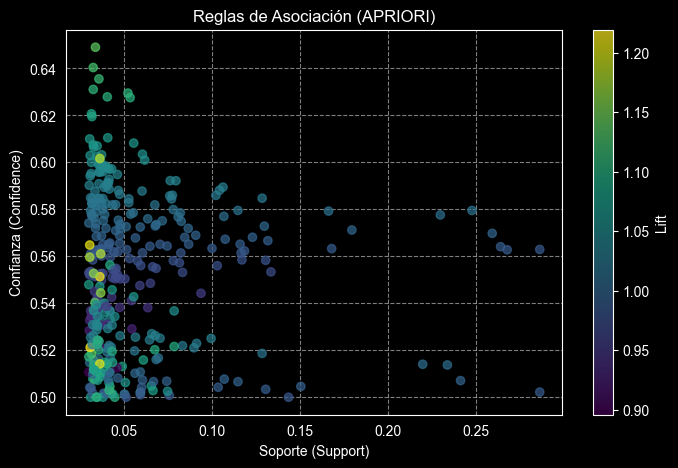

In [54]:
fp_model.graficar_dispersion()

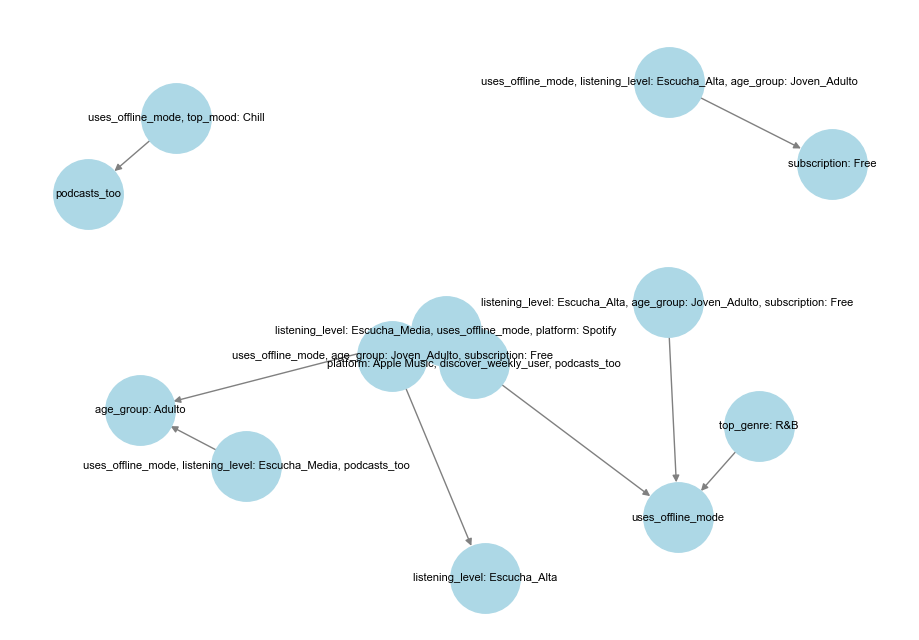

In [55]:
fp_model.graficar_red(top_n=8)

#### FP-Growth

In [56]:
fp_model.fit(metodo='fpgrowth', min_support=0.05, min_confidence=0.6)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"(uses_offline_mode, platform: Apple Music)",(discover_weekly_user),0.10275,0.57,0.06175,0.600973,1.054339,1.0,0.003183,1.077622,0.057440,0.101064,0.072031,0.354653
1,(top_genre: R&B),(discover_weekly_user),0.08525,0.57,0.05350,0.627566,1.100993,1.0,0.004908,1.154567,0.100278,0.088907,0.133874,0.360713
2,"(uses_offline_mode, listening_level: Escucha_A...",(discover_weekly_user),0.09125,0.57,0.05550,0.608219,1.067051,1.0,0.003488,1.097552,0.069148,0.091622,0.088882,0.352794
3,"(top_genre: Pop, podcasts_too)",(discover_weekly_user),0.08300,0.57,0.05225,0.629518,1.104418,1.0,0.004940,1.160650,0.103103,0.086975,0.138414,0.360592
4,(subscription: Student),(discover_weekly_user),0.10025,0.57,0.06050,0.603491,1.058757,1.0,0.003357,1.084465,0.061679,0.099221,0.077887,0.354816


In [57]:
tabla_reglas = fp_model.ver_reglas(top_n=10, ordenar_por='lift', lift_minimo=1.10)
print(tabla_reglas)

                      antecedents             consequents  support  \
3  (top_genre: Pop, podcasts_too)  (discover_weekly_user)  0.05225   
1                (top_genre: R&B)  (discover_weekly_user)  0.05350   

   confidence      lift  
3    0.629518  1.104418  
1    0.627566  1.100993  


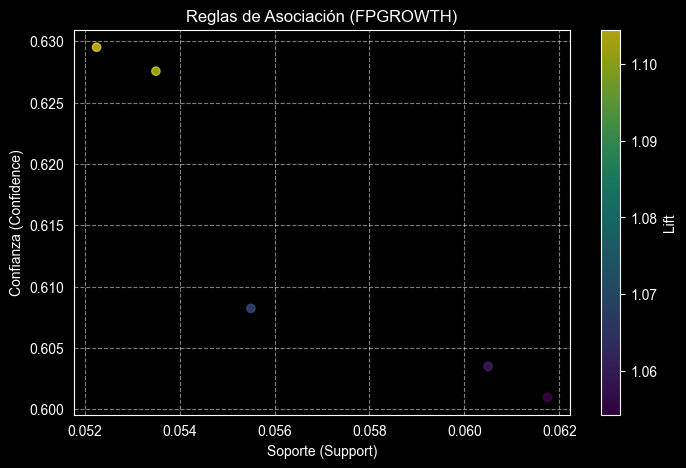

In [58]:
fp_model.graficar_dispersion()

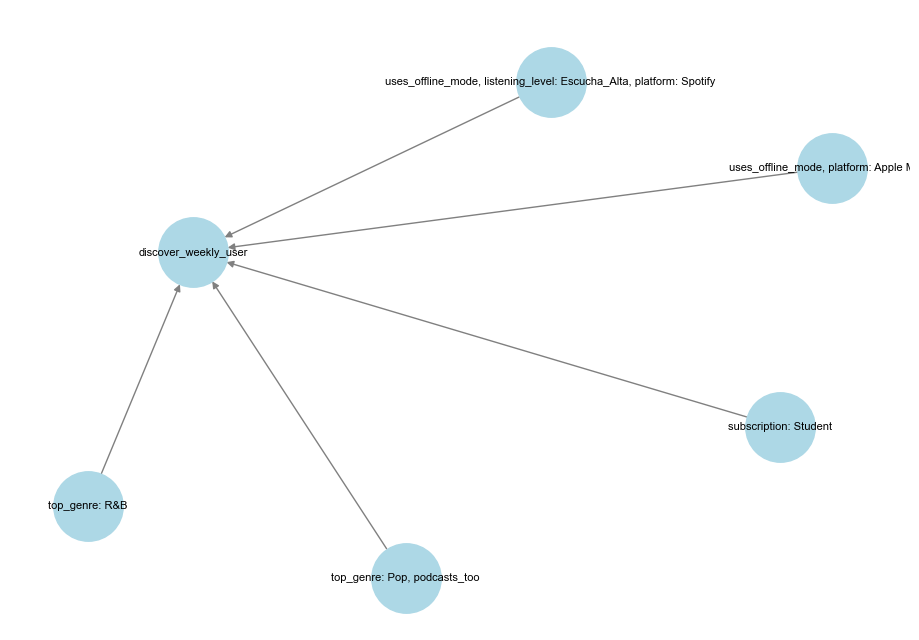

In [59]:
fp_model.graficar_red(top_n=8)

#### Eclat

In [48]:
fp_model.fit(metodo='eclat', min_support=0.03, min_confidence=0.6)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"(uses_offline_mode, subscription: Free, age_gr...",(listening_level: Escucha_Alta),0.06025,0.5085,0.03625,0.601660,1.183205,1.0,0.005613,1.233870,0.164765,0.068075,0.189542,0.336474
1,"(podcasts_too, platform: Spotify, age_group: J...",(discover_weekly_user),0.05725,0.5700,0.03450,0.602620,1.057228,1.0,0.001868,1.082088,0.057418,0.058203,0.075861,0.331573
2,"(uses_offline_mode, platform: Apple Music)",(discover_weekly_user),0.10275,0.5700,0.06175,0.600973,1.054339,1.0,0.003183,1.077622,0.057440,0.101064,0.072031,0.354653
3,"(uses_offline_mode, platform: Apple Music, pod...",(discover_weekly_user),0.05100,0.5700,0.03075,0.602941,1.057792,1.0,0.001680,1.082963,0.057570,0.052097,0.076607,0.328444
4,"(top_mood: Sleep, age_group: Adulto)",(discover_weekly_user),0.05350,0.5700,0.03250,0.607477,1.065748,1.0,0.002005,1.095476,0.065179,0.054992,0.087155,0.332247
5,(top_genre: R&B),(discover_weekly_user),0.08525,0.5700,0.05350,0.627566,1.100993,1.0,0.004908,1.154567,0.100278,0.088907,0.133874,0.360713
6,"(uses_offline_mode, listening_level: Escucha_A...",(discover_weekly_user),0.09125,0.5700,0.05550,0.608219,1.067051,1.0,0.003488,1.097552,0.069148,0.091622,0.088882,0.352794
7,"(listening_level: Escucha_Baja, subscription: ...",(discover_weekly_user),0.05250,0.5700,0.03150,0.600000,1.052632,1.0,0.001575,1.075000,0.052770,0.053299,0.069767,0.327632
8,"(top_mood: Sad, podcasts_too)",(discover_weekly_user),0.06075,0.5700,0.03650,0.600823,1.054076,1.0,0.001872,1.077216,0.054620,0.061422,0.071682,0.332429
9,"(top_genre: Pop, podcasts_too)",(discover_weekly_user),0.08300,0.5700,0.05225,0.629518,1.104418,1.0,0.004940,1.160650,0.103103,0.086975,0.138414,0.360592


In [49]:
tabla_reglas = fp_model.ver_reglas(top_n=10, ordenar_por='lift', lift_minimo=1.15)
print(tabla_reglas)

                                         antecedents  \
0  (uses_offline_mode, subscription: Free, age_gr...   

                       consequents  support  confidence      lift  
0  (listening_level: Escucha_Alta)  0.03625     0.60166  1.183205  


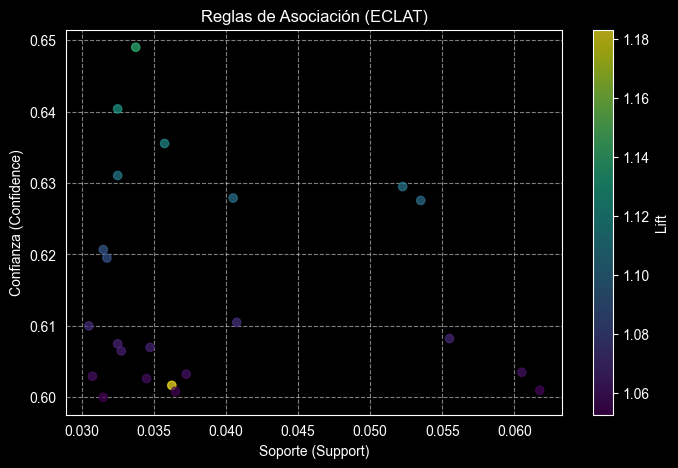

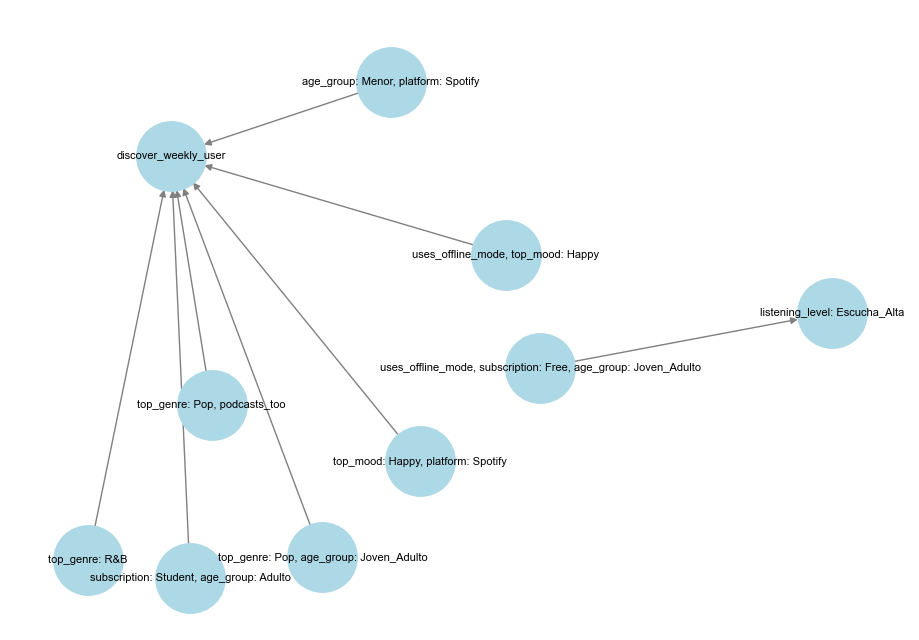

In [50]:
fp_model.graficar_dispersion()
fp_model.graficar_red(top_n=8)